# Лабораторная работа № 1. Исследование алгоритма KNN

**Цель работы** — исследовать применение метода ближайших соседей к классификации и регрессии. На первом этапе выбираем наборы данных, проверяем их и фиксируем разбиение для всех пяти лабораторных.

- **Wall-Following Robot Navigation Data.** По 24 ультразвуковым измерениям нужно выбрать манёвр для робота, который движется вдоль стены. Это задача многоклассовой классификации. [Описание UCI](https://archive.ics.uci.edu/dataset/194/wall+following+robot+navigation+data)
- **CPU Activity.** По системным счётчикам того же интервала измерения оцениваем долю времени работы процессоров в пользовательском режиме. Такая оценка полезна для мониторинга, когда показатель загрузки недоступен, а счётчики собраны. Это задача регрессии. [Описание OpenML](https://www.openml.org/d/44132)

## Загрузка и проверка таблиц

Загрузим оба локальных CSV и выведем первые пять строк, размер, типы столбцов, число пропусков и описательную статистику. Обзор всей таблицы нужен для отчёта. Параметры преобразований и моделей по нему не рассчитываем.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

robot = pd.read_csv("data/wall_following_robot_24.csv")
cpu = pd.read_csv("data/cpu_act_44132.csv")

for name, table in [("Wall-Following", robot), ("CPU Activity", cpu)]:
    print(f"{name}: {table.shape[0]} строк, {table.shape[1]} столбцов")
    display(table.head(5))
    display(pd.DataFrame({
        "Тип данных": table.dtypes.astype(str),
        "Пропуски": table.isna().sum(),
    }))
    print(f"Всего пропусков: {table.isna().sum().sum()}")
    display(table.describe(include="all").T)

Wall-Following: 5456 строк, 25 столбцов


,US1,US2,US3,US4,US5,US6,US7,US8,US9,US10,...,US16,US17,US18,US19,US20,US21,US22,US23,US24,class
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,...,0.593,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429,Slight-Right-Turn
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429,Slight-Right-Turn
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429,Slight-Right-Turn
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429,Slight-Right-Turn
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429,Slight-Right-Turn


,Тип данных,Пропуски
US1,float64,0
US2,float64,0
US3,float64,0
US4,float64,0
US5,float64,0
US6,float64,0
US7,float64,0
US8,float64,0
US9,float64,0
US10,float64,0


Всего пропусков: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
US1,5456.0,NaN,NaN,NaN,1.471617,0.802801,0.4,0.921,1.335,1.814,5.0
US2,5456.0,NaN,NaN,NaN,2.327043,1.410146,0.437,1.362,1.9045,2.6815,5.025
US3,5456.0,NaN,NaN,NaN,2.489347,1.247435,0.47,1.53875,2.064,2.73925,5.029
US4,5456.0,NaN,NaN,NaN,2.796501,1.309368,0.833,1.731,2.458,4.0935,5.017
US5,5456.0,NaN,NaN,NaN,2.958552,1.339225,1.12,1.774,2.667,4.3145,5.0
US6,5456.0,NaN,NaN,NaN,2.893073,1.282575,1.114,1.78575,2.6825,3.83525,5.005
US7,5456.0,NaN,NaN,NaN,3.351113,1.413692,1.122,1.93075,3.2255,5.0,5.008
US8,5456.0,NaN,NaN,NaN,2.540397,1.111554,0.859,1.618,2.172,3.193,5.087
US9,5456.0,NaN,NaN,NaN,3.125621,1.356965,0.836,1.79975,2.802,5.0,5.0
US10,5456.0,NaN,NaN,NaN,2.832386,1.307843,0.81,1.636,2.679,3.52625,5.022


CPU Activity: 8192 строк, 22 столбцов


,lread,lwrite,scall,sread,swrite,fork,exec,rchar,wchar,pgout,...,pgscan,atch,pgin,ppgin,pflt,vflt,runqsz,freemem,freeswap,usr
0,6.0,2.0,1036.0,103.0,114.0,1.00,1.00,172076.0,355965.0,0.00,...,0.00,0.00,2.00,4.00,73.60,89.00,2.0,6527.0,1851864.0,90.0
1,1.0,0.0,2165.0,205.0,101.0,0.40,1.20,43107.0,44139.0,4.80,...,181.40,0.20,85.40,88.20,19.40,161.80,3.0,130.0,1131931.0,88.0
2,62.0,77.0,3806.0,258.0,166.0,1.40,1.40,492142.0,268706.0,4.80,...,79.20,2.20,7.60,12.20,68.00,218.80,5.2,256.0,1314590.0,85.0
3,5.0,0.0,4721.0,256.0,177.0,0.99,2.58,524787.0,174964.0,14.51,...,189.86,1.99,4.17,24.85,95.63,248.91,1.0,233.0,972606.0,81.0
4,42.0,55.0,3949.0,249.0,244.0,2.60,4.60,197289.0,529200.0,4.20,...,0.00,1.40,1.80,2.20,219.60,297.20,3.4,331.0,1013805.0,79.0


,Тип данных,Пропуски
lread,float64,0
lwrite,float64,0
scall,float64,0
sread,float64,0
swrite,float64,0
fork,float64,0
exec,float64,0
rchar,float64,0
wchar,float64,0
pgout,float64,0


Всего пропусков: 0


,count,mean,std,min,25%,50%,75%,max
lread,8192.0,1.955969e+01,53.353799,0.0,2.00,7.0,20.000,1845.00
lwrite,8192.0,1.310620e+01,29.891726,0.0,0.00,1.0,10.000,575.00
scall,8192.0,2.306318e+03,1633.617322,109.0,1012.00,2051.5,3317.250,12493.00
sread,8192.0,2.104800e+02,198.980146,6.0,86.00,166.0,279.000,5318.00
swrite,8192.0,1.500582e+02,160.478980,7.0,63.00,117.0,185.000,5456.00
fork,8192.0,1.884554e+00,2.479493,0.0,0.40,0.8,2.200,20.12
exec,8192.0,2.791998e+00,5.212456,0.0,0.20,1.2,2.800,59.56
rchar,8192.0,1.970137e+05,239480.830770,278.0,33864.25,124779.5,267669.250,2526649.00
wchar,8192.0,9.589829e+04,140756.862281,1498.0,22935.50,46620.0,106148.000,1801623.00
pgout,8192.0,2.285317e+00,5.307038,0.0,0.00,0.0,2.400,81.44


## Распределение целевых переменных

Для манёвров построим столбчатую диаграмму и посчитаем доли классов. Для доли времени работы CPU в пользовательском режиме построим гистограмму.

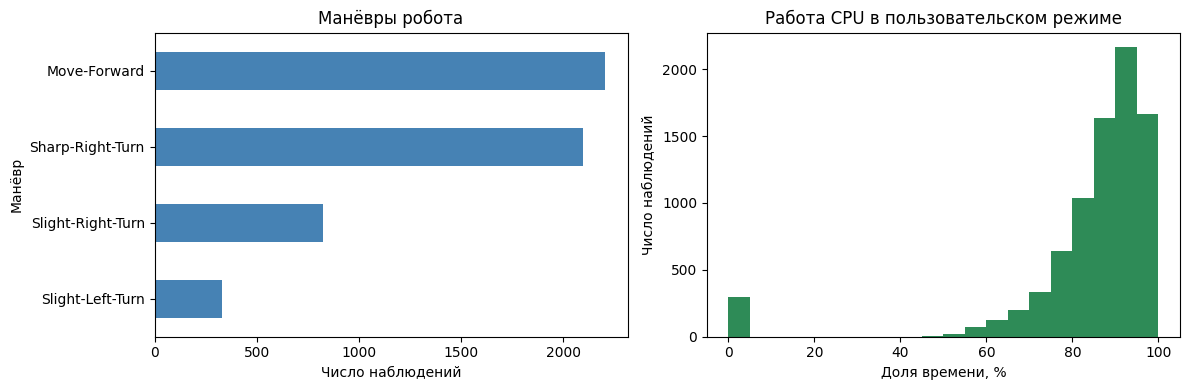

,Число наблюдений,"Доля, %"
class,,
Move-Forward,2205,40.41
Sharp-Right-Turn,2097,38.43
Slight-Right-Turn,826,15.14
Slight-Left-Turn,328,6.01


In [2]:
class_counts = robot["class"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Манёвры робота", xlabel="Число наблюдений", ylabel="Манёвр")
axes[1].hist(cpu["usr"], bins=20, range=(0, 100), color="seagreen")
axes[1].set(title="Работа CPU в пользовательском режиме",
            xlabel="Доля времени, %", ylabel="Число наблюдений")
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Число наблюдений": class_counts,
    "Доля, %": (100 * class_counts / len(robot)).round(2),
}))

Прямое движение и резкие правые повороты вместе составляют 78,85% наблюдений. Небольшой левый поворот встречается в 6,01% строк, примерно в 6,7 раза реже прямого движения. Данные собраны при движении по часовой стрелке вдоль стены, а наблюдения записывались через равные интервалы. Поэтому распределение отражает, сколько времени робот выполнял каждый манёвр на этом маршруте. По одной таблице нельзя установить точную причину редкости каждого манёвра.

## Признаки, целевые переменные и разбиение

У робота оставляем 24 показания датчиков. Наблюдения записывались с частотой 9 Гц на четырёх кругах, поэтому соседние строки могут быть похожи. Случайное перемешивание распределило бы соседние измерения между обучением и тестом. Берём последние 20% строк для теста и исключаем 90 строк перед границей, то есть около 10 секунд записи. Это фиксированный зазор для уменьшения зависимости у границы. В CSV нет номеров кругов, поэтому разбиение не гарантирует независимости маршрутов или отсутствия похожих измерений с разных кругов.

Для CPU Activity берём последние 20% строк в порядке исходного CSV. В первичном описании указано, что измерения снимались каждые 5 секунд в двух периодах сбора. В CSV нет времени и идентификатора периода. Разбиение по порядку сохраняет отдельный блок строк и не перемешивает возможных соседей, но оценку нельзя интерпретировать как прогноз на будущий период. Границы периодов по этому файлу неизвестны. [Описание OpenML](https://api.openml.org/api/v1/json/data/44132)

Зафиксируем границы по номерам строк с отсчётом от нуля. Во всех пяти лабораторных используем эти же CSV в исходном порядке и те же границы. Любое масштабирование, отбор признаков и настройку в следующих этапах выполняем только на обучающих данных. Если понадобится валидация, выделяем её внутри обучающей части. Тест оставляем для итоговой оценки.

In [3]:
X_robot = robot.drop(columns="class")
y_robot = robot["class"]
X_cpu = cpu.drop(columns="usr")
y_cpu = cpu["usr"]

# Правая граница среза не включается.
robot_train = slice(0, 4274)
robot_test = slice(4364, 5456)
cpu_train = slice(0, 6553)
cpu_test = slice(6553, 8192)

assert len(robot) == robot_test.stop and len(cpu) == cpu_test.stop

X_robot_train, X_robot_test = X_robot.iloc[robot_train], X_robot.iloc[robot_test]
y_robot_train, y_robot_test = y_robot.iloc[robot_train], y_robot.iloc[robot_test]
X_cpu_train, X_cpu_test = X_cpu.iloc[cpu_train], X_cpu.iloc[cpu_test]
y_cpu_train, y_cpu_test = y_cpu.iloc[cpu_train], y_cpu.iloc[cpu_test]

print(f"Робот: обучение — {len(X_robot_train)}, тест — {len(X_robot_test)}, "
      f"зазор — {robot_test.start - robot_train.stop}")
print(f"CPU: обучение — {len(X_cpu_train)}, тест — {len(X_cpu_test)}")
display(pd.DataFrame({
    "Обучение": y_robot_train.value_counts(),
    "Тест": y_robot_test.value_counts(),
}).fillna(0).astype(int))

Робот: обучение — 4274, тест — 1092, зазор — 90
CPU: обучение — 6553, тест — 1639


,Обучение,Тест
class,,
Move-Forward,1725,429
Sharp-Right-Turn,1655,408
Slight-Right-Turn,673,148
Slight-Left-Turn,221,107


## Проверка возможной утечки

У робота по описанию UCI все входные столбцы — показания датчиков в текущий момент. Метку манёвра исключаем из признаков. У CPU сверяем схему с OpenML: `sys`, `wio` и `idle` описаны в документации исходных измерений как другие доли времени CPU. Вместе с `usr` они описывают распределение времени процессора и могли бы раскрыть целевую долю через дополнение до 100%. В версии 44132 эти три столбца отсутствуют. Оставшиеся признаки — системные счётчики, размер очереди процессов и показатели памяти. Для выбранной задачи предполагаем, что они доступны в момент оценки за тот же интервал. [Схема OpenML](https://api.openml.org/api/v1/json/data/features/44132)

Проверим отсутствие общих индексов и полностью совпадающих векторов между обучением и тестом. На обучающей части CPU проверим точные копии `usr` и корреляции с ним. Корреляция служит подсказкой для проверки смысла признака. Она сама по себе не доказывает утечку, а отсутствие точного совпадения не исключает более сложной зависимости.

In [4]:
assert list(X_robot.columns) == [f"US{i}" for i in range(1, 25)]
cpu_features = (
    "lread lwrite scall sread swrite fork exec rchar wchar pgout ppgout "
    "pgfree pgscan atch pgin ppgin pflt vflt runqsz freemem freeswap"
).split()
assert list(X_cpu.columns) == cpu_features
assert {"usr", "sys", "wio", "idle"}.isdisjoint(X_cpu.columns)

for name, train, test in [
    ("Робот", X_robot_train, X_robot_test),
    ("CPU", X_cpu_train, X_cpu_test),
]:
    assert train.index.intersection(test.index).empty
    matches = train.drop_duplicates().merge(test.drop_duplicates(), on=list(train.columns))
    print(f"{name}: совпадающих наборов признаков между обучением и тестом — {len(matches)}")

copies = X_cpu_train.eq(y_cpu_train, axis=0).all()
print("Точных копий usr среди обучающих признаков:", int(copies.sum()))
correlations = X_cpu_train.corrwith(y_cpu_train)
display(correlations.sort_values(key=abs, ascending=False).round(3).to_frame("Корреляция с usr"))

Робот: совпадающих наборов признаков между обучением и тестом — 0
CPU: совпадающих наборов признаков между обучением и тестом — 0
Точных копий usr среди обучающих признаков: 0


,Корреляция с usr
freeswap,0.685
runqsz,-0.624
vflt,-0.417
pflt,-0.368
fork,-0.359
sread,-0.353
rchar,-0.332
scall,-0.320
swrite,-0.303
wchar,-0.290


У обеих таблиц совпадающих векторов между выборками нет. Среди обучающих столбцов CPU точных копий `usr` нет. Признаки CPU сохраняем по их смыслу и доступности для оценки за тот же интервал. Проверка совпадений не измеряет сходство соседних наблюдений робота, поэтому сохраняем последовательное разбиение с зазором.

## Метрики для следующих этапов

- **Accuracy** — доля верно предсказанных манёвров. Показывает общую точность классификации, на которую сильнее влияют частые классы.
- **F1-macro** — среднее значение F1 по четырём классам с равными весами. Учитывает точность и полноту для каждого манёвра и помогает заметить ошибки на редком левом повороте.
- **MAE** — средняя абсолютная ошибка оценки `usr` в процентных пунктах. Её можно интерпретировать как среднюю величину отклонения прогноза от измеренной доли.
- **RMSE** — корень из средней квадратичной ошибки в процентных пунктах. Эта метрика сильнее реагирует на крупные отклонения, чем MAE.
- **R²** — безразмерная оценка ошибки относительно постоянного прогноза, равного среднему фактическому значению `usr` на оцениваемой выборке. Единица соответствует точному прогнозу, ноль — ошибке на уровне этого среднего, отрицательное значение — большей ошибке.

## 2. Создание бейзлайна и оценка качества

### Классификация манёвров робота

Обучим `KNeighborsClassifier` с параметрами по умолчанию на подготовленной обучающей выборке. На тестовой выборке посчитаем Accuracy и F1-macro и построим матрицу ошибок. Используем исходные признаки в их исходном масштабе.

,Accuracy,F1-macro
Модель,,
KNN по умолчанию,0.783,0.7715


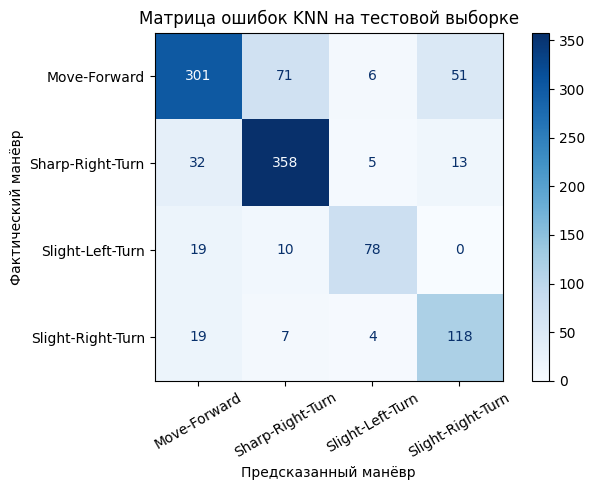

In [5]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

robot_baseline = KNeighborsClassifier()
robot_baseline.fit(X_robot_train, y_robot_train)
y_robot_pred = robot_baseline.predict(X_robot_test)

baseline_classification = pd.DataFrame(
    {
        "Accuracy": [accuracy_score(y_robot_test, y_robot_pred)],
        "F1-macro": [f1_score(y_robot_test, y_robot_pred, average="macro")],
    },
    index=pd.Index(["KNN по умолчанию"], name="Модель"),
)
display(baseline_classification.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_robot_test, y_robot_pred, labels=robot_baseline.classes_,
    cmap="Blues", values_format="d", xticks_rotation=30, ax=ax,
)
ax.set(
    title="Матрица ошибок KNN на тестовой выборке",
    xlabel="Предсказанный манёвр",
    ylabel="Фактический манёвр",
)
fig.tight_layout()
plt.show()

### Регрессия CPU Activity

Обучим `KNeighborsRegressor` с параметрами по умолчанию на подготовленной обучающей выборке. На тесте посчитаем MAE, RMSE и R². На графике сравним предсказания с фактическими значениями `usr`. Диагональ показывает точное совпадение.

,"MAE, п. п.","RMSE, п. п.",R²
Модель,,,
KNN по умолчанию,4.602,6.5426,0.854


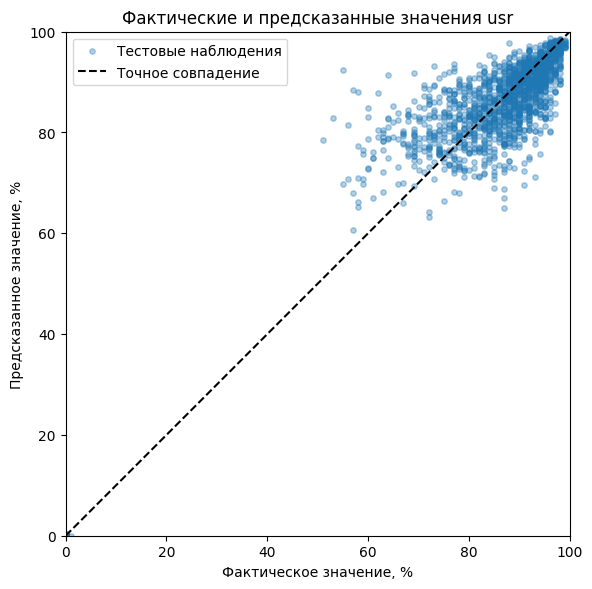

In [6]:
cpu_baseline = KNeighborsRegressor()
cpu_baseline.fit(X_cpu_train, y_cpu_train)
y_cpu_pred = cpu_baseline.predict(X_cpu_test)

baseline_regression = pd.DataFrame(
    {
        "MAE, п. п.": [mean_absolute_error(y_cpu_test, y_cpu_pred)],
        "RMSE, п. п.": [mean_squared_error(y_cpu_test, y_cpu_pred) ** 0.5],
        "R²": [r2_score(y_cpu_test, y_cpu_pred)],
    },
    index=pd.Index(["KNN по умолчанию"], name="Модель"),
)
display(baseline_regression.round(4))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_cpu_test, y_cpu_pred, s=15, alpha=0.35, label="Тестовые наблюдения")
ax.plot([0, 100], [0, 100], "--", color="black", label="Точное совпадение")
ax.set(
    title="Фактические и предсказанные значения usr",
    xlabel="Фактическое значение, %",
    ylabel="Предсказанное значение, %",
    xlim=(0, 100),
    ylim=(0, 100),
    aspect="equal",
)
ax.legend()
fig.tight_layout()
plt.show()

### Выводы

- **Классификация.** Accuracy составила 78,30%, F1-macro — 0,7715. Небольшой левый поворот модель верно распознала в 78 из 107 случаев. Общую долю правильных ответов дополняет F1-macro, в которой каждый манёвр имеет одинаковый вес.
- **Регрессия.** Средняя абсолютная ошибка составила 4,60 п. п., RMSE — 6,54 п. п., R² — 0,8540. По квадратичной ошибке модель лучше постоянного прогноза по среднему фактическому значению на тесте.

Таблицы `baseline_classification` и `baseline_regression` содержат метрики с полной точностью для дальнейшего сравнения.

## 3. Улучшение бейзлайна

Проверим три гипотезы для обеих задач:

1. `StandardScaler` может улучшить качество, если признаки с большим разбросом слишком сильно влияют на расстояние до соседей.
2. Выбор числа соседей из 3, 5, 7, 11, 15 и 21 может улучшить качество. Малое число соседей лучше учитывает локальные особенности, а большое сглаживает отдельные наблюдения.
3. Веса `distance` могут улучшить предсказания, если более близкие соседи информативнее. Сравним с равными весами `uniform`.

Сначала проверим три последовательных разбиения внутри обучающих выборок. У робота оставим 90 строк между обучающей и валидационной частями каждого фолда. У CPU используем последовательные блоки строк без зазора, как в основном разбиении. Для робота выведем число наблюдений каждого класса в обеих частях фолда.

In [7]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

robot_cv = TimeSeriesSplit(n_splits=3, gap=90)
cpu_cv = TimeSeriesSplit(n_splits=3)

fold_counts = []
for fold, (train_idx, val_idx) in enumerate(robot_cv.split(X_robot_train), start=1):
    assert val_idx[0] - train_idx[-1] - 1 == 90
    for part, idx in [("Обучение", train_idx), ("Валидация", val_idx)]:
        counts = y_robot_train.iloc[idx].value_counts().reindex(robot_baseline.classes_, fill_value=0)
        fold_counts.append({"Фолд": fold, "Часть": part, **counts.to_dict()})

robot_fold_classes = pd.DataFrame(fold_counts).set_index(["Фолд", "Часть"])
display(robot_fold_classes)
assert robot_fold_classes.gt(0).all().all()

Move-Forward  Sharp-Right-Turn  Slight-Left-Turn  \
Фолд Часть                                                         
1    Обучение            388               375                39   
     Валидация           406               421                55   
2    Обучение            812               776                95   
     Валидация           408               397                88   
3    Обучение           1235              1193               183   
     Валидация           465               432                38   

                Slight-Right-Turn  
Фолд Часть                         
1    Обучение                 178  
     Валидация                186  
2    Обучение                 365  
     Валидация                175  
3    Обучение                 505  
     Валидация                133

Проверим все 24 комбинации параметров для каждой задачи. В `Pipeline` масштабирование обучается только на обучающей части каждого фолда. Для робота выбираем максимальный средний F1-macro, для CPU — минимальный средний MAE. В sklearn для поиска используется `neg_mean_absolute_error`, поэтому в таблицах меняем знак. После выбора `GridSearchCV` переобучает победившую модель на всей обучающей выборке.

In [8]:
knn_grid = {
    "scale": ["passthrough", StandardScaler()],
    "knn__n_neighbors": [3, 5, 7, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
}

robot_search = GridSearchCV(
    Pipeline([("scale", "passthrough"), ("knn", KNeighborsClassifier())]),
    knn_grid, scoring="f1_macro", cv=robot_cv, refit=True, error_score="raise",
)
cpu_search = GridSearchCV(
    Pipeline([("scale", "passthrough"), ("knn", KNeighborsRegressor())]),
    knn_grid, scoring="neg_mean_absolute_error", cv=cpu_cv, refit=True,
    error_score="raise",
)
robot_search.fit(X_robot_train, y_robot_train)
cpu_search.fit(X_cpu_train, y_cpu_train)

# Эти словари можно использовать в собственной реализации.
best_robot_knn_params = {
    "standardize": isinstance(robot_search.best_params_["scale"], StandardScaler),
    "n_neighbors": robot_search.best_params_["knn__n_neighbors"],
    "weights": robot_search.best_params_["knn__weights"],
}
best_cpu_knn_params = {
    "standardize": isinstance(cpu_search.best_params_["scale"], StandardScaler),
    "n_neighbors": cpu_search.best_params_["knn__n_neighbors"],
    "weights": cpu_search.best_params_["knn__weights"],
}
best_knn_params = pd.DataFrame(
    [best_robot_knn_params, best_cpu_knn_params], index=["Робот", "CPU"]
)
display(best_knn_params)

,standardize,n_neighbors,weights
Робот,False,5,distance
CPU,True,7,distance


Сравним среднюю оценку по фолдам для каждого значения параметра, усредняя по одинаковому набору остальных настроек. Это покажет общую тенденцию по каждой гипотезе. Затем сравним исходную и лучшую комбинации на тех же фолдах. Победителя определяет оценка конкретной комбинации, поэтому он может отличаться от выбора по усреднённым строкам.

In [9]:
cv_summaries = {}
cv_comparisons = {}

for task, search, metric, sign in [
    ("Робот", robot_search, "F1-macro", 1),
    ("CPU", cpu_search, "MAE, п. п.", -1),
]:
    cv_results = pd.DataFrame(search.cv_results_)
    scores = pd.DataFrame({
        "Масштабирование": cv_results["param_scale"].map(
            lambda value: "StandardScaler" if isinstance(value, StandardScaler) else "Без масштабирования"
        ),
        "Число соседей": cv_results["param_knn__n_neighbors"].astype(int),
        "Веса": cv_results["param_knn__weights"],
        metric: sign * cv_results["mean_test_score"],
    })
    summary = pd.concat(
        {factor: scores.groupby(factor)[metric].mean()
         for factor in ["Масштабирование", "Число соседей", "Веса"]},
        names=["Параметр", "Значение"],
    ).to_frame(metric)
    default = (
        scores["Масштабирование"].eq("Без масштабирования")
        & scores["Число соседей"].eq(5)
        & scores["Веса"].eq("uniform")
    )
    comparison = pd.DataFrame(
        {metric: [scores.loc[default, metric].item(), sign * search.best_score_]},
        index=["Исходный", "Улучшенный"],
    )
    cv_summaries[task] = summary
    cv_comparisons[task] = comparison
    print(task)
    display(summary.round(4), comparison.round(4))

Робот


F1-macro
Параметр        Значение                     
Масштабирование StandardScaler         0.6864
                Без масштабирования    0.6871
Число соседей   3                      0.6971
                5                      0.6955
                7                      0.6860
                11                     0.6824
                15                     0.6838
                21                     0.6757
Веса            distance               0.6929
                uniform                0.6806

,F1-macro
Исходный,0.6895
Улучшенный,0.7055


CPU


MAE, п. п.
Параметр        Значение                       
Масштабирование StandardScaler           2.5535
                Без масштабирования      4.7204
Число соседей   3                        3.7316
                5                        3.6318
                7                        3.5845
                11                       3.5833
                15                       3.6178
                21                       3.6727
Веса            distance                 3.6146
                uniform                  3.6593

,"MAE, п. п."
Исходный,4.7868
Улучшенный,2.4307


Теперь оценим выбранные модели на прежних тестовых выборках. Сравним все пять метрик с таблицами раздела 2. Для каждой метрики построим отдельный график, чтобы сохранить её единицы и масштаб.

,Accuracy,F1-macro
Исходный,0.7830,0.7715
Улучшенный,0.8059,0.7947


,"MAE, п. п.","RMSE, п. п.",R²
Исходный,4.6020,6.5426,0.8540
Улучшенный,2.2199,4.2709,0.9378


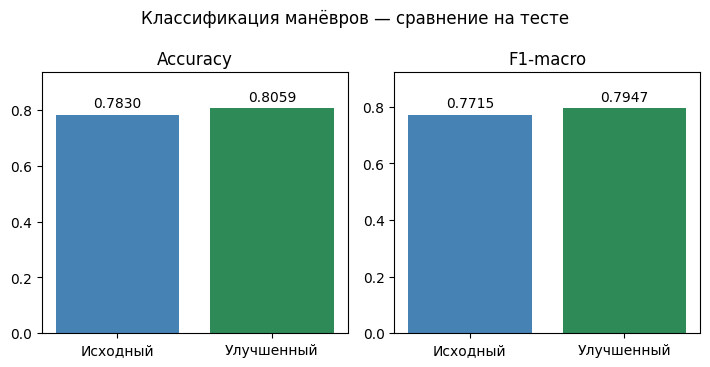

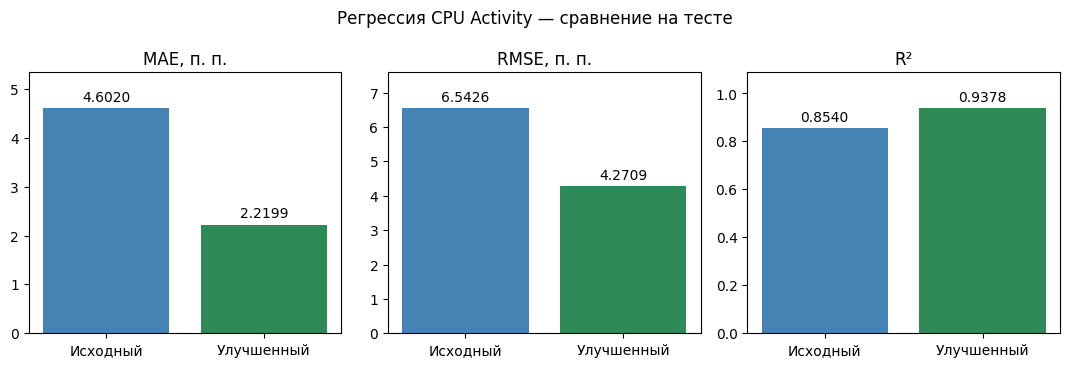

In [10]:
y_robot_improved = robot_search.best_estimator_.predict(X_robot_test)
y_cpu_improved = cpu_search.best_estimator_.predict(X_cpu_test)

classification_comparison = pd.DataFrame(
    [
        baseline_classification.iloc[0].to_dict(),
        {
            "Accuracy": accuracy_score(y_robot_test, y_robot_improved),
            "F1-macro": f1_score(y_robot_test, y_robot_improved, average="macro"),
        },
    ],
    index=["Исходный", "Улучшенный"],
)
regression_comparison = pd.DataFrame(
    [
        baseline_regression.iloc[0].to_dict(),
        {
            "MAE, п. п.": mean_absolute_error(y_cpu_test, y_cpu_improved),
            "RMSE, п. п.": mean_squared_error(y_cpu_test, y_cpu_improved) ** 0.5,
            "R²": r2_score(y_cpu_test, y_cpu_improved),
        },
    ],
    index=["Исходный", "Улучшенный"],
)
display(classification_comparison.round(4), regression_comparison.round(4))

for title, table in [
    ("Классификация манёвров", classification_comparison),
    ("Регрессия CPU Activity", regression_comparison),
]:
    fig, axes = plt.subplots(1, len(table.columns), figsize=(3.6 * len(table.columns), 3.7))
    for ax, metric in zip(axes, table.columns):
        bars = ax.bar(table.index, table[metric], color=["steelblue", "seagreen"])
        ax.bar_label(bars, fmt="%.4f", padding=3)
        ax.set_title(metric)
        ax.margins(y=0.16)
    fig.suptitle(title + " — сравнение на тесте")
    fig.tight_layout()
    plt.show()

### Выводы

- **Робот.** В среднем по сетке F1-macro без масштабирования составила 0,6871, со StandardScaler — 0,6864. Лучшее среднее по числу соседей было у `k=3` (0,6971), а `distance` в среднем оказался лучше `uniform` (0,6929 против 0,6806). Лучшая отдельная комбинация — `k=5`, `distance`, без масштабирования. С ней F1-macro выросла на кросс-валидации с 0,6895 до 0,7055 и на тесте с 0,7715 до 0,7947. Тестовая Accuracy выросла с 0,7830 до 0,8059.
- **CPU.** StandardScaler снизил средний MAE по сетке с 4,7204 до 2,5535 п. п. Лучшее среднее по числу соседей было у `k=11` (3,5833 п. п.), а `distance` в среднем дал меньшую ошибку, чем `uniform` (3,6146 против 3,6593 п. п.). Лучшая отдельная комбинация — `k=7`, `distance`, со StandardScaler. С ней MAE снизилась на кросс-валидации с 4,7868 до 2,4307 п. п. и на тесте с 4,6020 до 2,2199 п. п. На тесте RMSE снизилась с 6,5426 до 4,2709 п. п., а R² вырос с 0,8540 до 0,9378.

## 4. Самостоятельная реализация алгоритма KNN

При обучении KNN запоминает признаки и ответы обучающих объектов. Для нового объекта алгоритм вычисляет расстояния до обучающих строк и выбирает `k` ближайших. Евклидово расстояние между объектами с `p` признаками:

$$d(x,z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$

Классификатор выбирает класс с наибольшей суммой голосов, регрессор берёт взвешенное среднее ответов. При `uniform` все веса равны единице. При `distance` вес обратно пропорционален расстоянию. Если среди выбранных соседей есть точные совпадения, голосуют только они с одинаковыми весами.

Вычислим расстояния по одному объекту. При равных расстояниях сохраняем порядок обучающих строк. При равных суммах голосов выбираем первый класс в отсортированном списке.

In [11]:
import numpy as np


class NumpyKNN:
    def __init__(self, n_neighbors=5, weights="uniform"):
        self.n_neighbors = n_neighbors
        self.weights = weights

    def fit(self, X, y):
        features = np.asarray(X, dtype=float)
        targets = np.asarray(y)
        if features.ndim != 2 or targets.ndim != 1 or len(features) != len(targets):
            raise ValueError("X должна быть таблицей, а y — вектором той же длины.")
        if not isinstance(self.n_neighbors, (int, np.integer)) or not 1 <= self.n_neighbors <= len(features):
            raise ValueError("n_neighbors должно быть целым числом от 1 до размера выборки.")
        if self.weights not in ("uniform", "distance"):
            raise ValueError("weights должно быть uniform или distance.")
        self.X_train = features.copy()
        self.y_train = targets.copy()
        self.n_features_in_ = features.shape[1]
        return self

    def _neighbors(self, row):
        differences = self.X_train - row
        distances = np.sqrt(np.sum(differences ** 2, axis=1))
        indices = np.argsort(distances, kind="stable")[:self.n_neighbors]
        distances = distances[indices]

        if self.weights == "uniform":
            weights = np.ones(len(indices))
        elif np.any(distances == 0):
            weights = (distances == 0).astype(float)
        else:
            weights = 1 / distances
        return indices, weights

    def predict(self, X):
        if not hasattr(self, "n_features_in_"):
            raise ValueError("Сначала вызовите fit.")
        features = np.asarray(X, dtype=float)
        if features.ndim != 2 or features.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков должно совпадать с обучающей выборкой.")
        predictions = []
        for row in features:
            indices, weights = self._neighbors(row)
            predictions.append(self._predict_row(indices, weights))
        return np.asarray(predictions)


class NumpyKNNClassifier(NumpyKNN):
    def fit(self, X, y):
        super().fit(X, y)
        self.classes_, self.class_indices = np.unique(self.y_train, return_inverse=True)
        return self

    def _predict_row(self, indices, weights):
        votes = np.bincount(
            self.class_indices[indices], weights=weights, minlength=len(self.classes_)
        )
        return self.classes_[np.argmax(votes)]


class NumpyKNNRegressor(NumpyKNN):
    def _predict_row(self, indices, weights):
        return np.average(self.y_train[indices], weights=weights)

### Проверка на простых примерах

Для точки 1,5 ближайшие объекты — 1 и 2. Классы `A` и `B` набирают поровну голосов, поэтому ожидаем `A`. Для регрессии проверим обычное и взвешенное среднее. Для точки 8 проверим, что при весах `distance` учитываются только два точных совпадения. Отдельно проверим выбор соседа при равных расстояниях на границе `k`.

In [12]:
X_demo = [[0], [1], [2], [8], [8]]
y_demo_class = ["B", "B", "A", "A", "A"]
y_demo_value = [0, 10, 20, 40, 60]

demo_classifier = NumpyKNNClassifier(n_neighbors=2).fit(X_demo, y_demo_class)
assert demo_classifier.predict([[1.5]]).tolist() == ["A"]
assert NumpyKNNClassifier(n_neighbors=1).fit(X_demo, y_demo_class).predict([[1.5]]).tolist() == ["B"]

demo_classifier_distance = NumpyKNNClassifier(n_neighbors=5, weights="distance")
demo_classifier_distance.fit(X_demo, y_demo_class)
assert demo_classifier_distance.predict([[8]]).tolist() == ["A"]
weighted_vote = NumpyKNNClassifier(n_neighbors=3, weights="distance")
assert weighted_vote.fit(X_demo, y_demo_class).predict([[1.9]]).tolist() == ["A"]

demo_regressor = NumpyKNNRegressor(n_neighbors=2).fit(X_demo, y_demo_value)
np.testing.assert_allclose(demo_regressor.predict([[1.5]]), [15])
demo_regressor_distance = NumpyKNNRegressor(n_neighbors=2, weights="distance")
demo_regressor_distance.fit(X_demo, y_demo_value)
np.testing.assert_allclose(demo_regressor_distance.predict([[1.25]]), [12.5])
demo_regressor_zero = NumpyKNNRegressor(n_neighbors=3, weights="distance")
demo_regressor_zero.fit(X_demo, y_demo_value)
np.testing.assert_allclose(demo_regressor_zero.predict([[8]]), [50])

print("Все проверки пройдены.")

Все проверки пройдены.


### Обучение и предсказание

Сначала обучим собственные модели с настройками исходного бейзлайна. Затем возьмём параметры из раздела 3. Если выбрано масштабирование, добавим `StandardScaler` в `Pipeline`. При вызове `fit` он получает только обучающие признаки, а при `predict` применяет те же параметры к тесту.

In [13]:
robot_own = NumpyKNNClassifier(n_neighbors=5, weights="uniform")
cpu_own = NumpyKNNRegressor(n_neighbors=5, weights="uniform")
robot_own.fit(X_robot_train, y_robot_train)
cpu_own.fit(X_cpu_train, y_cpu_train)

robot_own_improved = Pipeline([
    ("scale", StandardScaler() if best_robot_knn_params["standardize"] else "passthrough"),
    ("knn", NumpyKNNClassifier(
        n_neighbors=best_robot_knn_params["n_neighbors"],
        weights=best_robot_knn_params["weights"],
    )),
])
cpu_own_improved = Pipeline([
    ("scale", StandardScaler() if best_cpu_knn_params["standardize"] else "passthrough"),
    ("knn", NumpyKNNRegressor(
        n_neighbors=best_cpu_knn_params["n_neighbors"],
        weights=best_cpu_knn_params["weights"],
    )),
])
robot_own_improved.fit(X_robot_train, y_robot_train)
cpu_own_improved.fit(X_cpu_train, y_cpu_train)

y_robot_own = robot_own.predict(X_robot_test)
y_cpu_own = cpu_own.predict(X_cpu_test)
y_robot_own_improved = robot_own_improved.predict(X_robot_test)
y_cpu_own_improved = cpu_own_improved.predict(X_cpu_test)

### Итоговые результаты

Соберём по четыре варианта для каждой задачи. Для библиотечных моделей возьмём сохранённые результаты раздела 3, для собственных посчитаем те же метрики. Дополнительно сравним предсказания попарно. Равные метрики сами по себе не гарантируют одинаковых ответов.

In [14]:
model_names = [
    "Исходный sklearn",
    "Улучшенный sklearn",
    "Собственная реализация",
    "Улучшенная собственная реализация",
]

classification_final = pd.DataFrame(
    classification_comparison.to_dict(orient="records")
    + [
        {
            "Accuracy": accuracy_score(y_robot_test, prediction),
            "F1-macro": f1_score(y_robot_test, prediction, average="macro"),
        }
        for prediction in [y_robot_own, y_robot_own_improved]
    ],
    index=pd.Index(model_names, name="Модель"),
)
regression_final = pd.DataFrame(
    regression_comparison.to_dict(orient="records")
    + [
        {
            "MAE, п. п.": mean_absolute_error(y_cpu_test, prediction),
            "RMSE, п. п.": mean_squared_error(y_cpu_test, prediction) ** 0.5,
            "R²": r2_score(y_cpu_test, prediction),
        }
        for prediction in [y_cpu_own, y_cpu_own_improved]
    ],
    index=pd.Index(model_names, name="Модель"),
)

display(classification_final.round(4), regression_final.round(4))

robot_disagreements = [
    int(np.count_nonzero(y_robot_own != y_robot_pred)),
    int(np.count_nonzero(y_robot_own_improved != y_robot_improved)),
]
cpu_max_differences = [
    float(np.max(np.abs(y_cpu_own - y_cpu_pred))),
    float(np.max(np.abs(y_cpu_own_improved - y_cpu_improved))),
]
print("Робот, число разных ответов (исходный и улучшенный):", robot_disagreements)
print("CPU, максимальная разница (исходный и улучшенный):",
      [f"{value:.3g}" for value in cpu_max_differences])

,Accuracy,F1-macro
Модель,,
Исходный sklearn,0.7830,0.7715
Улучшенный sklearn,0.8059,0.7947
Собственная реализация,0.7830,0.7715
Улучшенная собственная реализация,0.8059,0.7947


,"MAE, п. п.","RMSE, п. п.",R²
Модель,,,
Исходный sklearn,4.6020,6.5426,0.8540
Улучшенный sklearn,2.2199,4.2709,0.9378
Собственная реализация,4.6020,6.5426,0.8540
Улучшенная собственная реализация,2.2199,4.2709,0.9378


Робот, число разных ответов (исходный и улучшенный): [0, 0]
CPU, максимальная разница (исходный и улучшенный): ['0', '6.68e-13']


На графиках сравним четыре варианта по каждой метрике на тесте. Для каждой метрики используем отдельную ось.

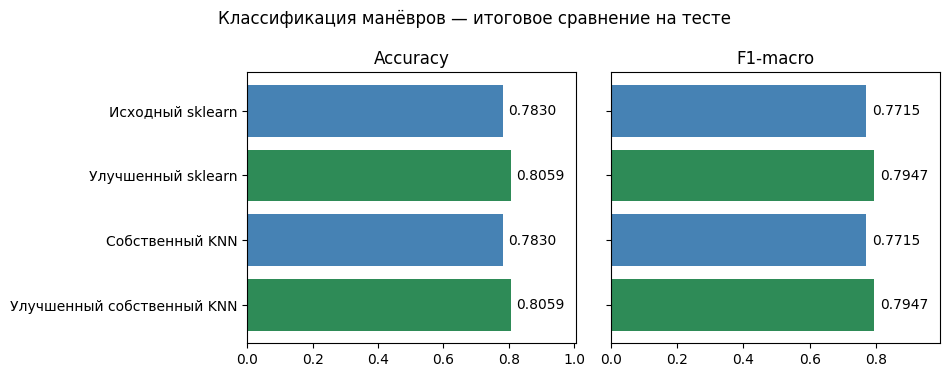

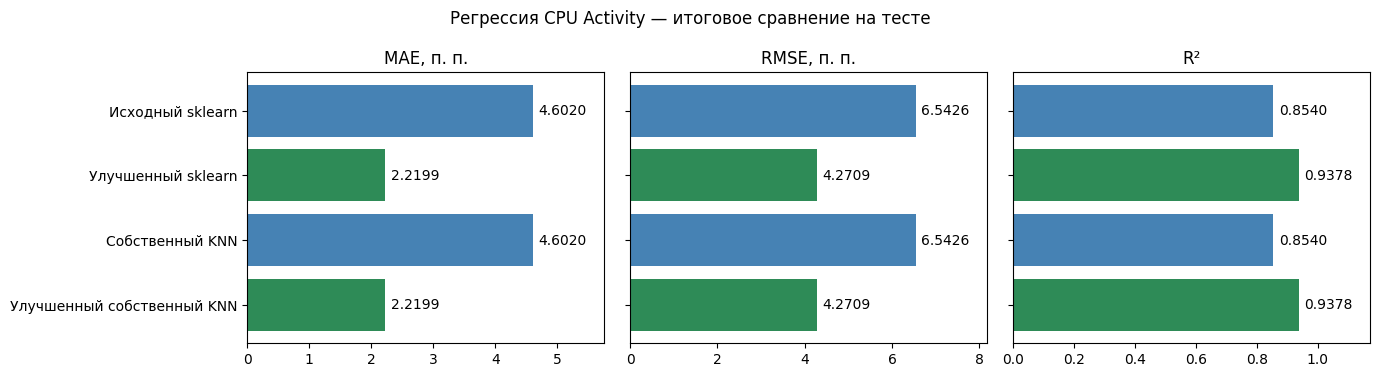

In [15]:
short_names = [
    "Исходный sklearn", "Улучшенный sklearn",
    "Собственный KNN", "Улучшенный собственный KNN",
]
colors = ["steelblue", "seagreen", "steelblue", "seagreen"]

for title, table in [
    ("Классификация манёвров", classification_final),
    ("Регрессия CPU Activity", regression_final),
]:
    fig, axes = plt.subplots(1, len(table.columns), figsize=(4.3 * len(table.columns) + 1, 3.8),
                             sharey=True)
    for ax, metric in zip(axes, table.columns):
        bars = ax.barh(short_names, table[metric], color=colors)
        ax.bar_label(bars, fmt="%.4f", padding=4)
        ax.set_title(metric)
        ax.margins(x=0.25)
    axes[0].invert_yaxis()
    fig.suptitle(title + " — итоговое сравнение на тесте")
    fig.tight_layout()
    plt.show()

### Общий вывод по лабораторной работе

- **Классификация.** После настройки собственного KNN Accuracy выросла с 0,7830 до 0,8059, а F1-macro — с 0,7715 до 0,7947. Для робота кросс-валидация выбрала взвешивание по расстоянию при пяти соседях без масштабирования. У собственного классификатора и sklearn различаются 0 исходных и 0 улучшенных предсказаний из 1092.
- **Регрессия.** После настройки собственного KNN MAE снизилась с 4,6020 до 2,2199 п. п., RMSE — с 6,5426 до 4,2709 п. п., а R² вырос с 0,8540 до 0,9378. Для CPU кросс-валидация выбрала StandardScaler, семь соседей и веса по расстоянию. Максимальные различия предсказаний собственного регрессора и sklearn составили 0 и 6,7e-13 п. п. Обе пары совпали с точностью вычислений с плавающей точкой.

На зафиксированных тестовых выборках выбранные настройки улучшили обе задачи. При одинаковых настройках возможные различия между реализациями связаны с порядком выбора равноудалённых соседей и округлением при вычислении расстояний и взвешенных сумм.